# Оценка качества модели: валидация, отбор признаков и подбор гиперпараметров

Продолжаем задачу прогноза месячной цены аренды квартир в Нью-Йорке по данным [RentHop (Kaggle)](https://www.kaggle.com/competitions/two-sigma-connect-rental-listing-inquiries/data). Модель здесь простая (линейная), главное в проекте: как честно измерить её качество.

Что сделано:
- свои функции разбиения на train / valid / test: случайное и по времени (out-of-time);
- свои K-Fold, Group K-Fold, Stratified K-Fold и TimeSeriesSplit со сверкой против sklearn;
- сравнение схем кросс-валидации: какая из них точнее предсказывает качество модели на будущих данных;
- отбор признаков четырьмя способами: веса Lasso, корреляция, permutation importance, SHAP;
- свои Grid Search и Random Search, сравнение с sklearn и Optuna.

Сплиты, кросс-валидация, отбор признаков и поиск гиперпараметров вынесены в `validation.py`.

## 1. Теория

### 1.1 Leave-one-out

Leave-one-out (LOO) это K-Fold, в котором число фолдов равно числу объектов: модель обучается на всех объектах, кроме одного, и проверяется на нём. Так повторяется для каждого объекта, итоговая метрика усредняется.

Плюсы:
1. для обучения используется почти весь датасет, это важно, когда данных очень мало;
2. разбиение детерминировано, случайности нет.

Минусы:
1. нужно обучить столько моделей, сколько объектов, поэтому для средних и больших датасетов метод слишком дорогой;
2. оценка на одном объекте очень шумная, а обучающие выборки почти одинаковые, поэтому итоговая оценка может иметь большую дисперсию;
3. нельзя использовать, если в данных есть группы или время: соседние объекты из той же группы попадут в train.

### 1.2 Grid Search, Random Search и байесовская оптимизация

**Grid Search.** Для каждого гиперпараметра задаём список значений и перебираем все комбинации. Каждую комбинацию оцениваем на валидации (или кросс-валидации) и выбираем лучшую. Число комбинаций растёт как произведение длин списков, поэтому метод подходит, когда гиперпараметров мало.

**Random Search.** Для каждого гиперпараметра задаём распределение (или список) и проверяем фиксированное число случайных комбинаций. Обычно качество сильно зависит только от части гиперпараметров. Сетка проверяет каждое значение важного параметра много раз в сочетании с разными значениями неважных, а случайный поиск за то же число итераций пробует гораздо больше разных значений важного параметра.

Оба метода не учитывают результаты предыдущих попыток: каждая новая комбинация выбирается независимо.

**Байесовская оптимизация** использует историю. По уже проверенным точкам строится вероятностная модель зависимости метрики от гиперпараметров (суррогатная модель: гауссовский процесс или, как в Optuna по умолчанию, TPE). Следующая точка выбирается через функцию выгоды (acquisition function), которая балансирует между:
- exploitation: проверять точки рядом с уже найденными хорошими;
- exploration: проверять области, где модель ещё мало знает и неопределённость большая.

Например, функция Expected Improvement выбирает точку, где ожидаемое улучшение над текущим лучшим результатом максимально. За счёт этого байесовская оптимизация обычно находит хорошие параметры за меньшее число запусков модели, но каждый шаг сложнее и сам метод плохо распараллеливается.

### 1.3 Методы отбора признаков

Отбор признаков нужен, чтобы уменьшить переобучение, ускорить обучение и сделать модель понятнее. Методы делят на группы:
- **Unsupervised:** не смотрят на таргет. Например, удаляем признаки с большой долей пропусков, с нулевой дисперсией или сильно скоррелированные между собой.
- **Filters (фильтры):** оценивают связь каждого признака с таргетом статистикой (корреляция, хи-квадрат, взаимная информация) до обучения модели. Быстро, но признаки рассматриваются по одному.
- **Wrappers (обёртки):** перебирают подмножества признаков и обучают на каждом модель (forward selection, backward elimination, RFE). Учитывают взаимодействие признаков, но дорого.
- **Embedded (встроенные):** отбор происходит во время обучения самой модели. Например, L1-регуляризация зануляет веса, деревья дают важности признаков.

**Корреляция Пирсона:** $r = \dfrac{\mathrm{cov}(X, Y)}{\sigma_X \sigma_Y}$, $-1 \le r \le 1$. Считаем корреляцию каждого признака с таргетом и оставляем признаки с наибольшим $|r|$. Видит только линейную связь и чувствительна к выбросам.

**Хи-квадрат:** проверяет независимость категориального признака и категориального таргета. Строим таблицу частот, считаем ожидаемые частоты при независимости и статистику $\chi^2 = \sum \frac{(O - E)^2}{E}$, где $O$ наблюдаемые, а $E$ ожидаемые частоты. Чем больше $\chi^2$, тем сильнее зависимость. Для числового таргета, как у нас, его сначала нужно разбить на интервалы.

**Lasso:** линейная модель с L1-штрафом, $L(w) = MSE + \alpha \sum |w_i|$. Штраф зануляет веса слабых признаков, поэтому Lasso сам отбирает признаки. Признаки нужно предварительно отмасштабировать, иначе веса несравнимы.

**Permutation importance:** обучаем модель, считаем метрику на валидации, затем перемешиваем значения одного признака и считаем метрику снова. Чем сильнее она упала, тем важнее признак. Работает с любой моделью, но для скоррелированных признаков важность делится между ними.

**SHAP:** метод на основе значений Шепли из теории игр. Прогноз раскладывается на сумму: среднее предсказание плюс вклад каждого признака. Вклад признака считается как его средний вклад по всем возможным подмножествам остальных признаков. Среднее $|SHAP|$ по выборке даёт глобальную важность. Для линейной модели SHAP считается точно и быстро.

## 2. Данные

In [1]:
import re
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import optuna

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import (train_test_split, KFold, GroupKFold, StratifiedKFold,
                                     TimeSeriesSplit, GridSearchCV, RandomizedSearchCV)

from validation import (data_split, data_split_valid, date_split, date_split_valid,
                        KFold_custom, GroupKFold_custom, StratifiedKFold_custom, TimeSeriesSplit_custom,
                        simple_feature_selection, permutation_importance,
                        custom_GridSearchCV, custom_RandomGridSearchCV, get_metrics, rmse)

optuna.logging.set_verbosity(optuna.logging.WARNING)

### 2.1 Признаки из списка удобств

В колонке `features` лежит список удобств квартиры. Убираем лишние символы и приводим названия к нижнему регистру (иначе `Laundry in Building` и `Laundry In Building` считались бы разными удобствами), считаем самые частые и делаем из топ-20 бинарные признаки.

In [2]:
def edit_features(arr):
    return [re.sub(r'[\[\]\'\"\s\-]', '', i).lower() for i in arr]
df = pd.read_json('data/train.json', convert_dates=['created'])
df['edited_features'] = df['features'].apply(edit_features)
all_features = []
for arr in df['edited_features']:
    all_features += arr
cnt = Counter(all_features)
cnt.most_common(20)

[('elevator', 26273),
 ('hardwoodfloors', 23559),
 ('catsallowed', 23540),
 ('dogsallowed', 22035),
 ('doorman', 20967),
 ('dishwasher', 20808),
 ('laundryinbuilding', 18944),
 ('nofee', 18079),
 ('fitnesscenter', 13257),
 ('prewar', 10501),
 ('laundryinunit', 9435),
 ('roofdeck', 7010),
 ('outdoorspace', 5270),
 ('diningroom', 5150),
 ('highspeedinternet', 4315),
 ('balcony', 3058),
 ('swimmingpool', 2730),
 ('newconstruction', 2608),
 ('terrace', 2313),
 ('exclusive', 2167)]

In [3]:
columns = [x[0] for x in cnt.most_common(20)]
X = df[['bathrooms', 'bedrooms', 'created', 'manager_id']].copy()
for i in columns:
    X[i] = df['edited_features'].apply(lambda x: 1 if i in x else 0)
X['price'] = df['price']

### 2.2 Выбросы

Убираем цены за пределами 1-го и 99-го перцентилей: в данных есть явные ошибки (цены в сотни тысяч долларов в месяц).

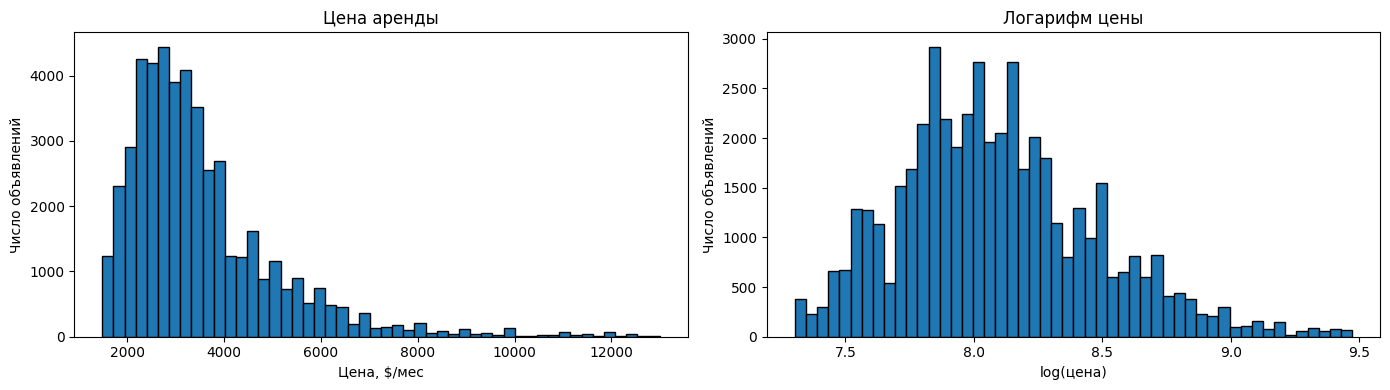

Объектов: 48343 | менеджеров: 3433 | даты: 2016-04-01 - 2016-06-29


In [4]:
q1 = X['price'].quantile(0.01)
q99 = X['price'].quantile(0.99)
X = X[(X['price'] > q1) & (X['price'] < q99)]

y = X['price']
X = X.drop(columns=['price'])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(y, bins=50, edgecolor='black')
ax[0].set(title='Цена аренды', xlabel='Цена, $/мес', ylabel='Число объявлений')
ax[1].hist(np.log(y), bins=50, edgecolor='black')
ax[1].set(title='Логарифм цены', xlabel='log(цена)', ylabel='Число объявлений')
plt.tight_layout()
plt.show()
print('Объектов:', X.shape[0], '| менеджеров:', X['manager_id'].nunique(),
      '| даты:', X['created'].min().date(), '-', X['created'].max().date())

Данные за три месяца 2016 года, около 14 объявлений на одного менеджера. Это важно для выбора схемы валидации: объявления одного менеджера похожи друг на друга, и время тоже может влиять на цену.

## 3. Разбиение на train / valid / test

In [5]:
X_train, X_test, y_train, y_test = data_split(X, y, test_size=0.3, random_state=21)
print('Случайно 70/30:', len(X_train), len(X_test))

X_train, X_valid, X_test, y_train, y_valid, y_test = data_split_valid(X, y, test_size=0.2, validation_size=0.2, random_state=21)
print('Случайно 60/20/20:', len(X_train), len(X_valid), len(X_test))

X_train, X_test, y_train, y_test = date_split(X, y, date_split='2016-06-01', date_column='created')
print('По дате (до 1 июня / после):', len(X_train), len(X_test))

X_train, X_valid, X_test, y_train, y_valid, y_test = date_split_valid(X, y, validation_date='2016-05-15', test_date='2016-06-01', date_column='created')
print('По дате на три части:', len(X_train), len(X_valid), len(X_test))
print('Пересечения по времени:', X_train['created'].max() < X_valid['created'].min(), X_valid['created'].max() < X_test['created'].min())

Случайно 70/30: 33840 14503
Случайно 60/20/20: 29005 9669 9669
По дате (до 1 июня / после): 31551 16792
По дате на три части: 23646 7905 16792
Пересечения по времени: True True


### 3.1 Детерминированность

Разбиение детерминировано, если при повторном запуске получаются те же самые выборки. Для этого фиксируем `random_state`: генератор случайных чисел выдаёт ту же последовательность, и перемешивание повторяется. Без этого метрики будут меняться от запуска к запуску, и нельзя будет понять, улучшила ли модель правка в коде или просто повезло с разбиением.

In [6]:
a = data_split(X, y, test_size=0.2, random_state=21)[1].index
b = data_split(X, y, test_size=0.2, random_state=21)[1].index
c = data_split(X, y, test_size=0.2, random_state=7)[1].index
print('Тот же random_state, тот же test:', a.equals(b))
print('Другой random_state, тот же test:', a.equals(c))

Тот же random_state, тот же test: True
Другой random_state, тот же test: False


## 4. Кросс-валидация: свои реализации и сверка со sklearn

Все классы повторяют интерфейс sklearn: `split(X, y, groups)` возвращает позиционные индексы train и test. Сравниваем индексы на маленьких примерах и на наших данных.

In [7]:
def same_splits(sk_splits, custom_splits):
    # совпадают ли индексы train и test во всех фолдах
    sk_splits, custom_splits = list(sk_splits), list(custom_splits)
    if len(sk_splits) != len(custom_splits):
        return False
    return all(np.array_equal(a[0], b[0]) and np.array_equal(a[1], b[1]) for a, b in zip(sk_splits, custom_splits))

def print_folds(splits, groups=None):
    for i, (train_index, test_index) in enumerate(splits):
        print(f'Fold {i}: train={train_index}, test={test_index}' + ('' if groups is None else f', test groups={groups[test_index]}'))

### 4.1 K-Fold

In [8]:
Xx = np.arange(12).reshape(6, 2)
print_folds(KFold_custom(n_splits=3).split(Xx))
print('Совпадает со sklearn (без перемешивания):', same_splits(KFold(n_splits=3).split(X), KFold_custom(n_splits=3).split(X)))
print('Совпадает со sklearn (с перемешиванием):', same_splits(KFold(n_splits=5, shuffle=True, random_state=21).split(X),
                                                               KFold_custom(n_splits=5, shuffle=True, random_state=21).split(X)))

Fold 0: train=[2 3 4 5], test=[0 1]
Fold 1: train=[0 1 4 5], test=[2 3]
Fold 2: train=[0 1 2 3], test=[4 5]
Совпадает со sklearn (без перемешивания): True
Совпадает со sklearn (с перемешиванием): True


### 4.2 Group K-Fold

Группы раскладываются по фолдам жадно: самая большая из оставшихся групп идёт в фолд, где сейчас меньше всего объектов. Порядок фолдов может отличаться от sklearn, поэтому проверяем главное: группы в train и test не пересекаются.

In [9]:
Xx = np.arange(12).reshape(6, 2)
groups_toy = np.array([0, 2, 0, 5, 3, 4])
print('sklearn:'); print_folds(GroupKFold(n_splits=3).split(Xx, groups=groups_toy), groups_toy)
print('custom:'); print_folds(GroupKFold_custom(n_splits=3).split(Xx, groups=groups_toy), groups_toy)

groups = X['manager_id'].values
for train_index, test_index in GroupKFold_custom(n_splits=5).split(X, groups=groups):
    print('Общих менеджеров в train и test:', len(set(groups[train_index]) & set(groups[test_index])), '| размер test:', len(test_index))

sklearn:
Fold 0: train=[1 3 4 5], test=[0 2], test groups=[0 0]
Fold 1: train=[0 1 2 5], test=[3 4], test groups=[5 3]
Fold 2: train=[0 2 3 4], test=[1 5], test groups=[2 4]
custom:
Fold 0: train=[1 3 4 5], test=[0 2], test groups=[0 0]
Fold 1: train=[0 2 3 4], test=[1 5], test groups=[2 4]
Fold 2: train=[0 1 2 5], test=[3 4], test groups=[5 3]
Общих менеджеров в train и test: 0 | размер test: 9669
Общих менеджеров в train и test: 0 | размер test: 9669
Общих менеджеров в train и test: 0 | размер test: 9669
Общих менеджеров в train и test: 0 | размер test: 9668
Общих менеджеров в train и test: 0 | размер test: 9668


### 4.3 Stratified K-Fold

Индексы каждого класса делим на `n_splits` частей подряд, и i-й фолд собираем из i-х частей всех классов. Распределение классов в каждом фолде получается таким же, как во всей выборке. Sklearn распределяет объекты немного иначе, поэтому индексы совпадают не полностью.

Таргет у нас числовой, поэтому для стратификации разбиваем цену на 15 квантильных интервалов.

In [10]:
Xx = np.zeros((11, 2))
yy = np.array([0, 0, 1, 1, 2, 2, 1, 0, 4, 4, 4])
print('sklearn:'); print_folds(StratifiedKFold(n_splits=2).split(Xx, yy))
print('custom:'); print_folds(StratifiedKFold_custom(n_splits=2).split(Xx, yy))

y_binned = pd.qcut(y, q=15, labels=False)

sklearn:
Fold 0: train=[ 3  5  6  7 10], test=[0 1 2 4 8 9]
Fold 1: train=[0 1 2 4 8 9], test=[ 3  5  6  7 10]
custom:
Fold 0: train=[ 5  6  7 10], test=[0 1 2 3 4 8 9]
Fold 1: train=[0 1 2 3 4 8 9], test=[ 5  6  7 10]


### 4.4 TimeSeriesSplit

Данные упорядочиваются по `date_field`, и каждый следующий фолд обучается на всём прошлом и проверяется на следующем куске. Индексы возвращаются в нумерации исходной таблицы, поэтому сортировать её заранее не нужно. Для сверки со sklearn сортируем таблицу сами.

In [11]:
Xx = np.arange(12).reshape(6, 2)
print_folds(TimeSeriesSplit_custom(n_splits=3).split(Xx))
print('Совпадает со sklearn:', same_splits(TimeSeriesSplit(n_splits=3).split(Xx), TimeSeriesSplit_custom(n_splits=3).split(Xx)))

X_sorted = X.sort_values('created', kind='stable')
y_sorted = y.loc[X_sorted.index]
print('Совпадает со sklearn на данных:', same_splits(TimeSeriesSplit(n_splits=5).split(X_sorted),
                                                     TimeSeriesSplit_custom(n_splits=5, date_field='created').split(X_sorted)))

# на неотсортированной таблице: train всегда раньше test
for train_index, test_index in TimeSeriesSplit_custom(n_splits=5, date_field='created').split(X):
    print('train до', X['created'].iloc[train_index].max().date(), '| test с', X['created'].iloc[test_index].min().date())

Fold 0: train=[0 1 2], test=[3]
Fold 1: train=[0 1 2 3], test=[4]
Fold 2: train=[0 1 2 3 4], test=[5]
Совпадает со sklearn: True
Совпадает со sklearn на данных: True
train до 2016-04-16 | test с 2016-04-16
train до 2016-05-02 | test с 2016-05-02
train до 2016-05-16 | test с 2016-05-16
train до 2016-06-01 | test с 2016-06-01
train до 2016-06-15 | test с 2016-06-15


### 4.5 Распределение таргета в фолдах: sklearn и свои реализации

In [12]:
def distribution(kfold, kfold_cust, X, y, y_split=None, groups=None, title=''):
    # y_split: по чему делим (для стратификации), y: что рисуем
    fig, axes = plt.subplots(nrows=kfold.get_n_splits(), ncols=2, figsize=(12, 3 * kfold.get_n_splits()))
    fig.suptitle(title, fontsize=16)
    splits = zip(kfold.split(X, y_split, groups), kfold_cust.split(X, y_split, groups))
    for i, ((train_1, test_1), (train_2, test_2)) in enumerate(splits):
        for j, (idx_1, idx_2, part) in enumerate([(train_1, train_2, 'train'), (test_1, test_2, 'test')]):
            axes[i, j].hist(y.iloc[idx_1], bins=30, alpha=0.5, label='sklearn', color='blue', density=True)
            axes[i, j].hist(y.iloc[idx_2], bins=30, alpha=0.5, label='custom', color='red', density=True)
            axes[i, j].set(title=f'Fold {i + 1}: {part}', xlabel='Цена, $/мес')
            axes[i, j].legend()
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

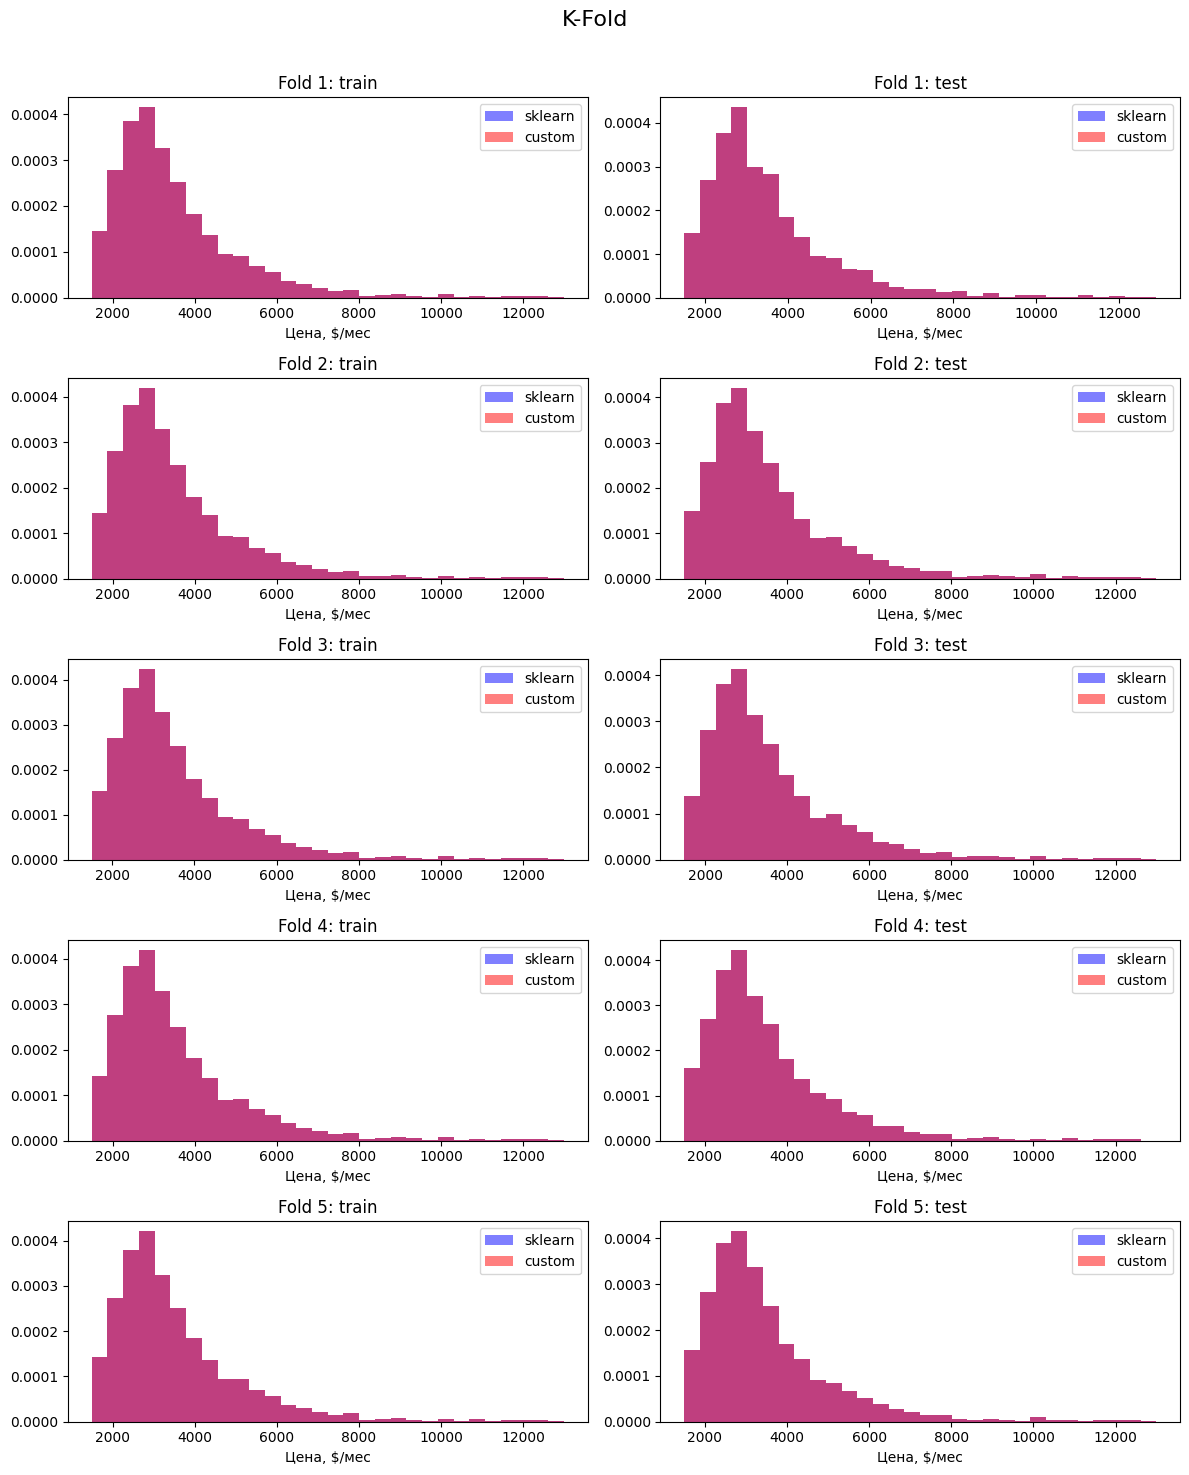

In [13]:
distribution(KFold(n_splits=5), KFold_custom(n_splits=5), X, y, title='K-Fold')

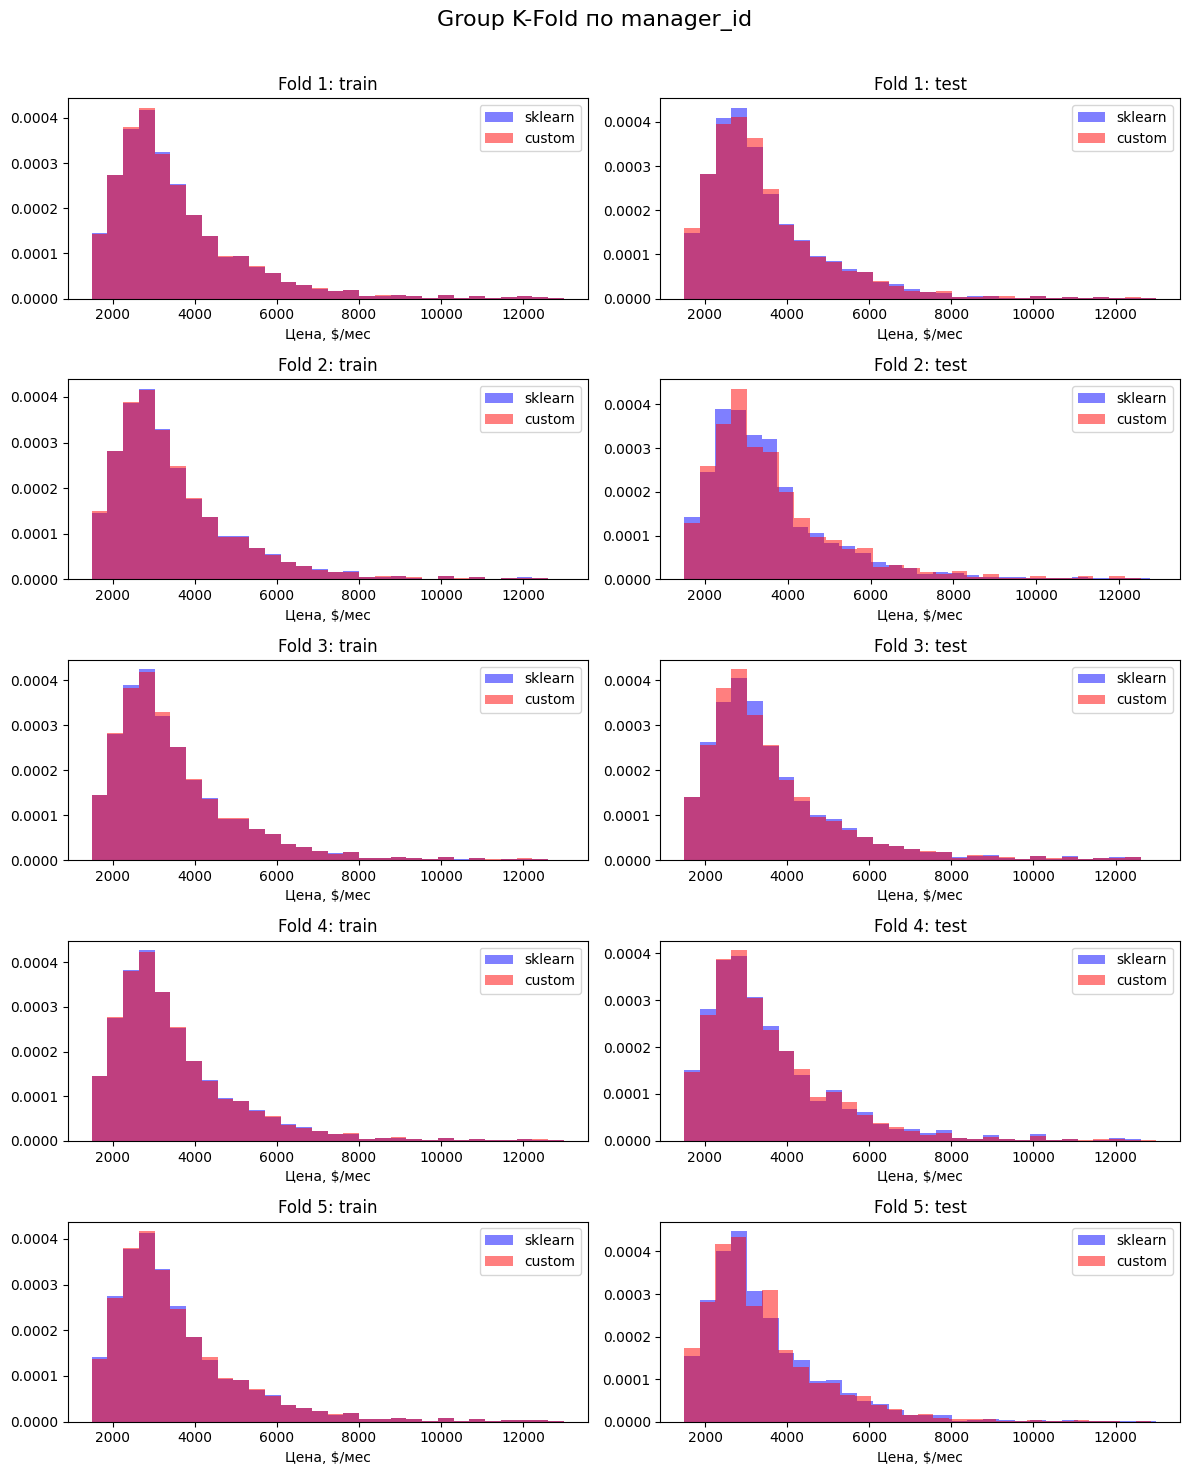

In [14]:
distribution(GroupKFold(n_splits=5), GroupKFold_custom(n_splits=5), X, y, groups=groups, title='Group K-Fold по manager_id')

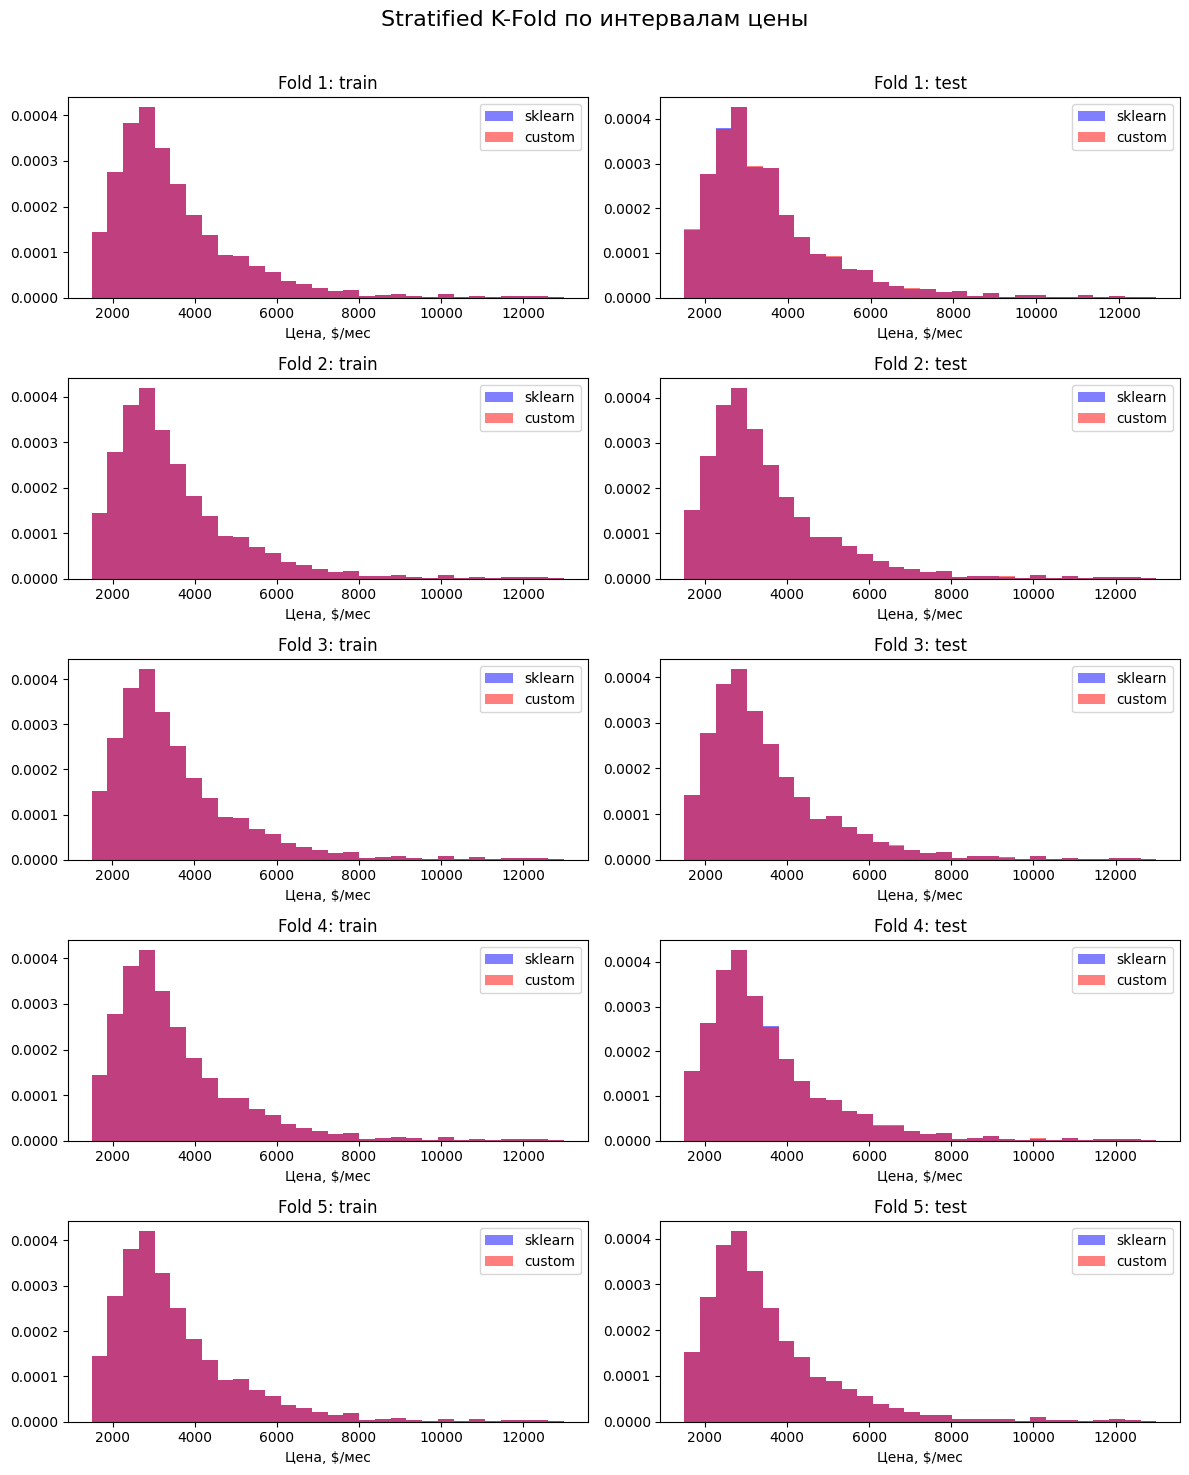

In [15]:
distribution(StratifiedKFold(n_splits=5), StratifiedKFold_custom(n_splits=5), X, y, y_split=y_binned, title='Stratified K-Fold по интервалам цены')

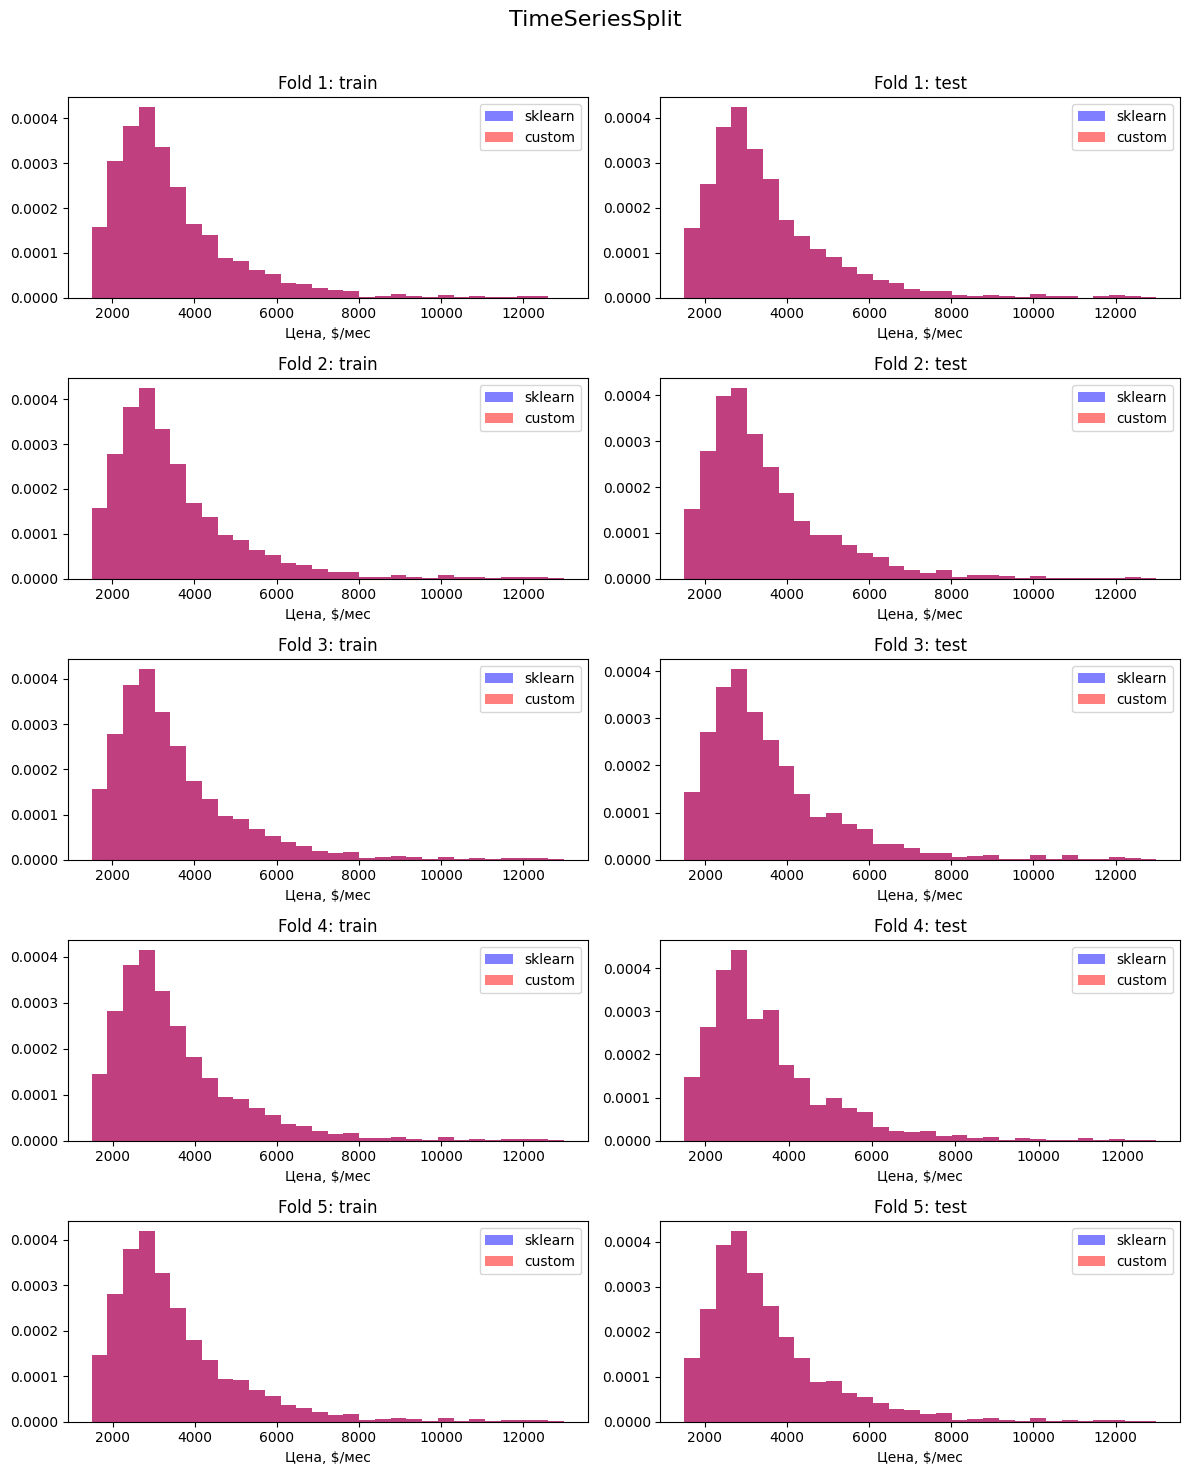

In [16]:
distribution(TimeSeriesSplit(n_splits=5), TimeSeriesSplit_custom(n_splits=5, date_field='created'), X_sorted, y_sorted, title='TimeSeriesSplit')

**Вывод:** у K-Fold и TimeSeriesSplit гистограммы sklearn и моей реализации совпадают полностью, потому что индексы одинаковые. У Stratified K-Fold в тестовых фолдах есть мелкие расхождения: sklearn раскладывает объекты по фолдам немного по-другому, но распределение цены во всех фолдах почти одинаковое, то есть стратификация работает. У Group K-Fold фолды отличаются сильнее, потому что группы попадают в фолды в другом порядке, и сравнивать фолды один к одному не совсем корректно. Главное, что менеджеры в train и test не пересекаются, а распределения train почти совпадают.

## 5. Какая схема валидации честнее

Схема валидации хороша, если её оценка близка к качеству модели на новых данных. Проверим это напрямую:
1. откладываем последние 20% объявлений по дате как «будущее» (holdout);
2. на оставшихся 80% оцениваем линейную регрессию каждой схемой кросс-валидации;
3. обучаем модель на всех 80% и считаем настоящую ошибку на holdout;
4. сравниваем: какая схема ошиблась в оценке меньше всего.

In [17]:
feature_cols = [c for c in X.columns if c not in ['created', 'manager_id']]

test_date = X['created'].quantile(0.8)
X_cv, X_hold, y_cv, y_hold = date_split(X, y, date_split=test_date, date_column='created')
y_cv_binned = pd.qcut(y_cv, q=15, labels=False)

schemes = {
    'K-Fold': (KFold_custom(n_splits=5), None, None),
    'K-Fold (shuffle)': (KFold_custom(n_splits=5, shuffle=True, random_state=21), None, None),
    'Group K-Fold (manager_id)': (GroupKFold_custom(n_splits=5), None, X_cv['manager_id'].values),
    'Stratified K-Fold (цена)': (StratifiedKFold_custom(n_splits=5), y_cv_binned, None),
    'TimeSeriesSplit': (TimeSeriesSplit_custom(n_splits=5, date_field='created'), None, None),
}

cv_rows = []
fold_mae = {}
for name, (cv, y_split, g) in schemes.items():
    maes, r2s = [], []
    for train_index, test_index in cv.split(X_cv, y_split, g):
        model = LinearRegression().fit(X_cv[feature_cols].iloc[train_index], y_cv.iloc[train_index])
        pred = model.predict(X_cv[feature_cols].iloc[test_index])
        maes.append(mean_absolute_error(y_cv.iloc[test_index], pred))
        r2s.append(r2_score(y_cv.iloc[test_index], pred))
    fold_mae[name] = maes
    cv_rows.append({'scheme': name, 'CV MAE': np.mean(maes), 'MAE std': np.std(maes),
                    'CV R2': np.mean(r2s), 'R2 std': np.std(r2s)})

model = LinearRegression().fit(X_cv[feature_cols], y_cv)
hold_pred = model.predict(X_hold[feature_cols])
hold_mae = mean_absolute_error(y_hold, hold_pred)
hold_r2 = r2_score(y_hold, hold_pred)

cv_table = pd.DataFrame(cv_rows).set_index('scheme')
cv_table['MAE holdout'] = hold_mae
cv_table['ошибка оценки MAE'] = cv_table['CV MAE'] - hold_mae
cv_table['R2 holdout'] = hold_r2
cv_table.round(3)

,CV MAE,MAE std,CV R2,R2 std,MAE holdout,ошибка оценки MAE,R2 holdout
scheme,,,,,,,
K-Fold,708.596,7.381,0.579,0.025,721.666,-13.070,0.572
K-Fold (shuffle),708.431,5.314,0.580,0.011,721.666,-13.235,0.572
Group K-Fold (manager_id),712.768,11.342,0.571,0.025,721.666,-8.898,0.572
Stratified K-Fold (цена),708.586,8.888,0.580,0.021,721.666,-13.081,0.572
TimeSeriesSplit,707.064,13.419,0.582,0.028,721.666,-14.602,0.572


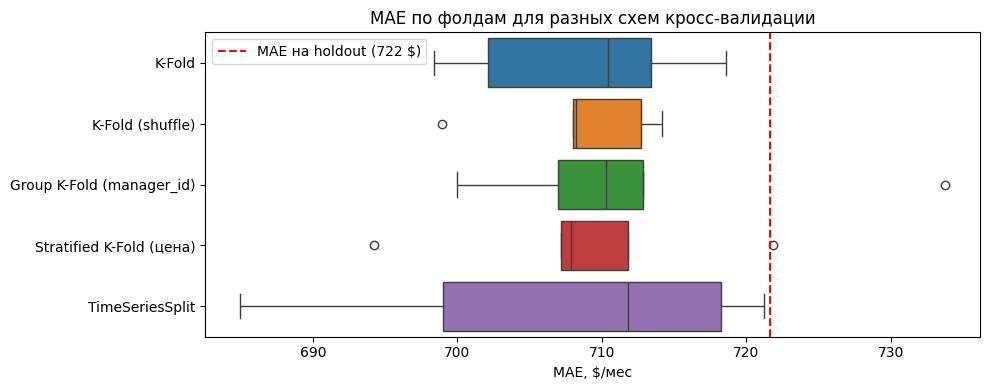

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=pd.DataFrame(fold_mae), orient='h', ax=ax)
ax.axvline(hold_mae, color='red', linestyle='--', label=f'MAE на holdout ({hold_mae:.0f} $)')
ax.set(title='MAE по фолдам для разных схем кросс-валидации', xlabel='MAE, $/мес')
ax.legend()
plt.tight_layout()
plt.savefig('images/cv_schemes.png', dpi=120)
plt.show()

**Какую схему выбрать.** Все схемы оказались немного оптимистичными: MAE на кросс-валидации на 9-15 \$ меньше, чем реальная ошибка на последних 20% дней (722 \$). Ближе всех Group K-Fold по manager_id (ошибка оценки около 9 \$). Видимо, часть оптимизма обычного K-Fold появляется из-за того, что объявления того же менеджера есть и в train, и в test. TimeSeriesSplit дал самую оптимистичную оценку и самый большой разброс по фолдам: первые фолды учатся на маленькой части данных, а ошибка заметно меняется от периода к периоду.

Разница между схемами небольшая (около 1%), потому что модель простая и почти не может «запомнить» менеджера. Для этой задачи я бы выбрал Group K-Fold по manager_id: модель будет предсказывать цену новых объявлений, в том числе от новых менеджеров, и эта схема даёт самую честную оценку.

Общие соображения:
- **K-Fold** подходит, когда объекты независимы и порядок не важен. Если таблица упорядочена (например, по времени), без перемешивания фолды получаются неоднородными.
- **Stratified K-Fold** важен, когда таргет несбалансирован или выборка маленькая: каждый фолд получает все диапазоны цен. На 48 тыс. объектов обычный K-Fold с перемешиванием и так почти стратифицирован.
- **Group K-Fold** нужен, когда модель будет применяться к новым группам. Например, к объявлениям менеджеров, которых не было в обучении. Иначе модель «узнаёт» менеджера по похожим объявлениям, и оценка получается завышенной.
- **TimeSeriesSplit** нужен, когда модель предсказывает будущее: обучаемся только на прошлом, как в реальной работе. Минус: первые фолды обучаются на малой части данных.

## 6. Отбор признаков

Делим данные **по дате** `created` на train / valid / test в пропорции 60/20/20, масштабируем признаки MinMaxScaler (обучаем его только на train) и обучаем Lasso. Коэффициент регуляризации подбираем на valid.

In [19]:
validation_date = X['created'].quantile(0.6)
test_date = X['created'].quantile(0.8)
X_train, X_valid, X_test, y_train, y_valid, y_test = date_split_valid(X, y, validation_date, test_date, date_column='created')
X_train, X_valid, X_test = X_train[feature_cols], X_valid[feature_cols], X_test[feature_cols]
print(len(X_train), len(X_valid), len(X_test))

scaler = MinMaxScaler().set_output(transform='pandas')
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

29006 9668 9669


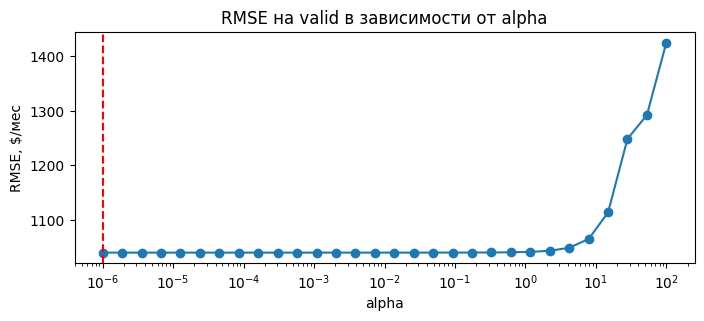

Лучший alpha: 1e-06


In [20]:
alphas = np.logspace(-6, 2, 30)
valid_rmse = []
for alpha in alphas:
    pred = Lasso(alpha=alpha, max_iter=10000).fit(X_train, y_train).predict(X_valid)
    valid_rmse.append(rmse(y_valid, pred))
best_alpha = alphas[np.argmin(valid_rmse)]

plt.figure(figsize=(8, 3))
plt.semilogx(alphas, valid_rmse, marker='o')
plt.axvline(best_alpha, color='red', linestyle='--')
plt.title('RMSE на valid в зависимости от alpha')
plt.xlabel('alpha')
plt.ylabel('RMSE, $/мес')
plt.show()
print('Лучший alpha:', best_alpha)

In [21]:
fs_results = []   # метрики моделей
fs_features = {}  # какие признаки выбрал каждый метод
fs_time = {}      # сколько секунд занял отбор

def fit_and_score(name, features):
    m = Lasso(alpha=best_alpha, max_iter=10000).fit(X_train[features], y_train)
    preds = [m.predict(X_train[features]), m.predict(X_valid[features]), m.predict(X_test[features])]
    fs_results.append(get_metrics(name, [y_train, y_valid, y_test], preds))
    return m

model = fit_and_score('Lasso, все 22 признака', feature_cols)

### 6.1 Топ-10 по весам Lasso

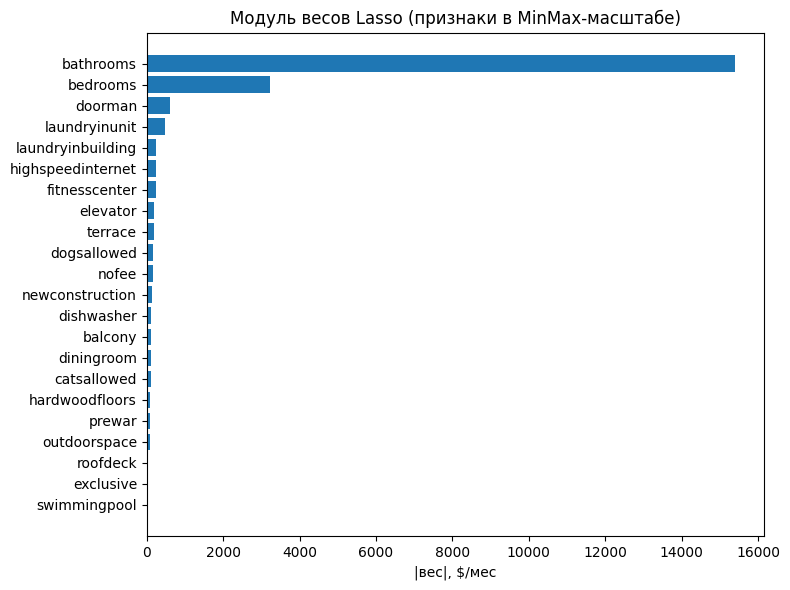

In [22]:
start = time.perf_counter()
imp_feat = pd.DataFrame({'Name': feature_cols, 'Importance': np.abs(model.coef_)}).sort_values(by='Importance', ascending=False)
fs_features['Веса Lasso'] = imp_feat['Name'].iloc[:10].tolist()
fs_time['Веса Lasso'] = time.perf_counter() - start

plt.figure(figsize=(8, 6))
plt.barh(imp_feat['Name'], imp_feat['Importance'])
plt.gca().invert_yaxis()
plt.title('Модуль весов Lasso (признаки в MinMax-масштабе)')
plt.xlabel('|вес|, $/мес')
plt.tight_layout()
plt.show()

fit_and_score('Lasso, топ-10 по весам', fs_features['Веса Lasso']);

### 6.2 Пропуски и корреляция

In [23]:
start = time.perf_counter()
fs_features['Корреляция'] = simple_feature_selection(X_train, y_train)
fs_time['Корреляция'] = time.perf_counter() - start
fit_and_score('Lasso, топ-10 по корреляции', fs_features['Корреляция']);

### 6.3 Permutation importance

Важность считаем на valid: на train модель могла запомнить шум, и важности получились бы завышенными.

In [24]:
start = time.perf_counter()
fs_features['Permutation'], imp = permutation_importance(model, X_valid, y_valid)
fs_time['Permutation'] = time.perf_counter() - start
fit_and_score('Lasso, топ-10 по permutation', fs_features['Permutation']);
pd.DataFrame(imp, columns=['feature', 'падение R2']).head(10)

,feature,падение R2
0,bathrooms,0.412097
1,bedrooms,0.200595
2,doorman,0.080522
3,laundryinunit,0.027641
4,laundryinbuilding,0.009386
5,elevator,0.008518
6,dogsallowed,0.008233
7,fitnesscenter,0.008085
8,nofee,0.005054
9,hardwoodfloors,0.003125


### 6.4 SHAP

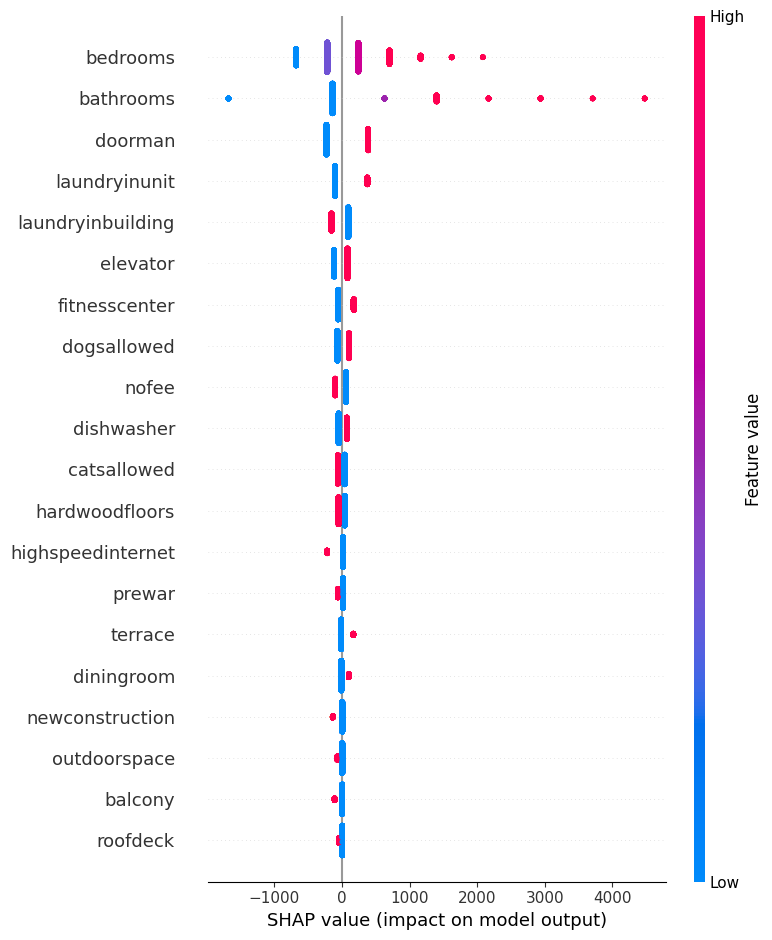

In [25]:
start = time.perf_counter()
explainer = shap.LinearExplainer(model, X_train)
shap_values = explainer(X_valid)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
shap_importance = sorted(zip(X_valid.columns, mean_abs_shap), key=lambda x: x[1], reverse=True)
fs_features['SHAP'] = [feat for feat, _ in shap_importance[:10]]
fs_time['SHAP'] = time.perf_counter() - start

shap.summary_plot(shap_values, X_valid, show=False)
plt.tight_layout()
plt.savefig('images/shap_summary.png', dpi=120)
plt.show()

fit_and_score('Lasso, топ-10 по SHAP', fs_features['SHAP']);

### 6.5 Сравнение методов: качество, скорость, стабильность

In [26]:
fs_table = pd.DataFrame(fs_results).set_index('model')
fs_table.round(3)

,MAE train,RMSE train,R2 train,MAE valid,RMSE valid,R2 valid,MAE test,RMSE test,R2 test
model,,,,,,,,,
"Lasso, все 22 признака",702.507,1024.237,0.578,718.091,1039.870,0.587,721.081,1035.292,0.571
"Lasso, топ-10 по весам",704.577,1029.501,0.573,723.160,1047.789,0.580,725.006,1041.456,0.566
"Lasso, топ-10 по корреляции",713.431,1039.027,0.565,732.084,1057.523,0.573,733.599,1050.770,0.558
"Lasso, топ-10 по permutation",706.736,1029.867,0.573,723.197,1046.056,0.582,725.144,1039.344,0.568
"Lasso, топ-10 по SHAP",706.974,1029.829,0.573,723.461,1046.507,0.581,725.280,1039.662,0.568


In [27]:
# какие признаки выбрал каждый метод
selected = pd.DataFrame({method: [1 if f in feats else 0 for f in feature_cols] for method, feats in fs_features.items()}, index=feature_cols)
selected['выбран раз'] = selected.sum(axis=1)
print('Время отбора, сек:', {k: round(v, 3) for k, v in fs_time.items()})
selected.sort_values('выбран раз', ascending=False)

Время отбора, сек: {'Веса Lasso': 0.002, 'Корреляция': 0.016, 'Permutation': 0.088, 'SHAP': 0.208}


,Веса Lasso,Корреляция,Permutation,SHAP,выбран раз
bathrooms,1,1,1,1,4
bedrooms,1,1,1,1,4
elevator,1,1,1,1,4
laundryinunit,1,1,1,1,4
fitnesscenter,1,1,1,1,4
doorman,1,1,1,1,4
dogsallowed,1,0,1,1,3
laundryinbuilding,1,0,1,1,3
nofee,0,0,1,1,2
dishwasher,0,1,0,1,2


In [28]:
# стабильность permutation importance: меняется ли топ-10 при другом seed
tops = [set(permutation_importance(model, X_valid, y_valid, random_state=s)[0]) for s in range(10)]
print('Признаки, попавшие в топ-10 хотя бы раз за 10 запусков:', len(set.union(*tops)))
print('Признаки, попавшие в топ-10 во всех 10 запусках:', len(set.intersection(*tops)))

Признаки, попавшие в топ-10 хотя бы раз за 10 запусков: 12
Признаки, попавшие в топ-10 во всех 10 запусках: 9


**Вывод:**
- Если оставить 10 признаков из 22, качество падает совсем немного: MAE на test вырос с 721 до 725 \$ для весов Lasso, permutation и SHAP. Хуже всех корреляция (734 \$): она смотрит на признаки по одному, поэтому взяла roofdeck и outdoorspace, но пропустила laundryinbuilding, который полезен вместе с остальными признаками.
- По скорости все методы быстрые: от 0.002 с (веса Lasso) до 0.2 с (SHAP). На таком датасете это не важно, но permutation и SHAP требуют обученной модели и много раз считают предсказания, поэтому на больших данных они заметно дороже.
- 6 признаков выбрали все четыре метода: bathrooms, bedrooms, doorman, elevator, laundryinunit, fitnesscenter.
- Permutation importance стабилен: за 10 запусков с разным seed 9 признаков всегда были в топ-10, менялось только последнее место.
- Лучший alpha для Lasso упёрся в нижнюю границу сетки (1e-6), то есть регуляризация здесь почти не нужна: признаков мало, данных много. Поэтому веса Lasso тут по сути веса обычной линейной регрессии.

## 7. Подбор гиперпараметров ElasticNet

Подбираем `alpha` и `l1_ratio`. Делим данные случайно 80/20: на 80% подбираем параметры кросс-валидацией, на 20% (test) только в конце измеряем итоговое качество.

In [29]:
X_train, X_test, y_train, y_test = data_split(X[feature_cols], y, test_size=0.2, random_state=21)

scaler = MinMaxScaler().set_output(transform='pandas')
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

elnet = ElasticNet(max_iter=10000)
hp_results = []

def score_search(name, model, seconds, params):
    row = get_metrics(name, [y_train, y_test], [model.predict(X_train), model.predict(X_test)], parts=('train', 'test'))
    row['время, сек'] = seconds
    row['alpha'] = params['alpha']
    row['l1_ratio'] = params['l1_ratio']
    hp_results.append(row)

### 7.1 Grid Search

In [30]:
parameters = {
    'alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1, 10],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

start = time.perf_counter()
clf = GridSearchCV(elnet, param_grid=parameters, scoring='r2', cv=KFold(n_splits=5), n_jobs=-1).fit(X_train, y_train)
score_search('Grid Search (sklearn)', clf, time.perf_counter() - start, clf.best_params_)

start = time.perf_counter()
gscv = custom_GridSearchCV(elnet, params=parameters, scoring='r2').fit(X_train, y_train)
score_search('Grid Search (custom)', gscv, time.perf_counter() - start, gscv.best_params_)
print('sklearn:', clf.best_params_, '| custom:', {k: gscv.best_params_[k] for k in parameters})

sklearn: {'alpha': 0.0001, 'l1_ratio': 0.9} | custom: {'alpha': 0.0001, 'l1_ratio': 0.9}


### 7.2 Random Search

In [31]:
param_grid = {
    'alpha': np.logspace(-4, 2, 200),
    'l1_ratio': np.linspace(0.01, 0.99, 100)
}

start = time.perf_counter()
clf = RandomizedSearchCV(elnet, param_grid, n_iter=30, scoring='r2', cv=KFold(n_splits=5), random_state=21, n_jobs=-1).fit(X_train, y_train)
score_search('Random Search (sklearn)', clf, time.perf_counter() - start, clf.best_params_)

start = time.perf_counter()
rgscv = custom_RandomGridSearchCV(elnet, param_grid, n_iter=30, scoring='r2', random_state=21).fit(X_train, y_train)
score_search('Random Search (custom)', rgscv, time.perf_counter() - start, rgscv.best_params_)

### 7.3 Optuna на отдельной валидационной выборке

Test в подборе не участвует: от train отрезаем 25% под valid (это 20% всего датасета), Optuna максимизирует R2 на valid. Потом обучаем модель с найденными параметрами на всём train и один раз считаем метрики на test.

In [32]:
X_tr, X_val, y_tr, y_val = data_split(X_train, y_train, test_size=0.25, random_state=21)

def objective(trial):
    alpha = trial.suggest_float('alpha', 1e-4, 100, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.01, 0.99)
    model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000).fit(X_tr, y_tr)
    return r2_score(y_val, model.predict(X_val))

start = time.perf_counter()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=100)
best_model = ElasticNet(**study.best_params, max_iter=10000).fit(X_train, y_train)
score_search('Optuna, valid', best_model, time.perf_counter() - start, study.best_params)

### 7.4 Optuna на кросс-валидации

In [33]:
def objective_cv(trial):
    alpha = trial.suggest_float('alpha', 1e-4, 100, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.01, 0.99)
    kf = KFold_custom(n_splits=5)
    score = 0
    for train_idx, test_idx in kf.split(X_train):
        model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000)
        model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        score += r2_score(y_train.iloc[test_idx], model.predict(X_train.iloc[test_idx]))
    return score / kf.get_n_splits()

start = time.perf_counter()
study_cv = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_cv.optimize(objective_cv, n_trials=50)
best_model = ElasticNet(**study_cv.best_params, max_iter=10000).fit(X_train, y_train)
score_search('Optuna, 5-fold CV', best_model, time.perf_counter() - start, study_cv.best_params)

### 7.5 Сравнение подходов

In [34]:
pd.DataFrame(hp_results).set_index('model').round(4)

,MAE train,RMSE train,R2 train,MAE test,RMSE test,R2 test,"время, сек",alpha,l1_ratio
model,,,,,,,,,
Grid Search (sklearn),707.7332,1024.0819,0.5773,723.2892,1049.4205,0.5838,9.9976,0.0001,0.9000
Grid Search (custom),707.7332,1024.0819,0.5773,723.2892,1049.4205,0.5838,35.8767,0.0001,0.9000
Random Search (sklearn),709.1041,1025.7027,0.5760,725.4353,1052.6894,0.5812,2.6881,0.0003,0.4654
Random Search (custom),707.8129,1024.1326,0.5773,723.4645,1049.6858,0.5836,20.5783,0.0001,0.8019
"Optuna, valid",707.7053,1024.0746,0.5773,723.2168,1049.3163,0.5839,32.1850,0.0002,0.9899
"Optuna, 5-fold CV",707.7161,1024.0764,0.5773,723.2457,1049.3574,0.5838,93.6624,0.0001,0.9605


**Вывод:**
- Все методы нашли очень маленький alpha (1e-4 - 3e-4) и получили почти одинаковое качество: R2 на test 0.581-0.584, MAE 723-725 \$. Регуляризация этой модели не нужна, поэтому и подбирать тут особо нечего.
- Мой Grid Search нашёл те же параметры, что и sklearn, с теми же метриками, но работал в 3.5 раза дольше (36 с против 10 с): sklearn считает комбинации параллельно (`n_jobs=-1`), а мой перебор идёт по одной.
- Random Search из sklearn за 30 итераций попал в чуть худшую точку (l1_ratio 0.47), мой случайный поиск оказался ближе к оптимуму. При малом числе итераций результат случайного поиска во многом зависит от удачи.
- Optuna на отдельной valid дала лучший R2 на test, но разница с остальными только в четвёртом знаке. Optuna на кросс-валидации работала дольше всех (94 с), зато её оценка надёжнее, чем по одной valid-выборке.
- Test ни в одном методе не участвовал в подборе, поэтому эти метрики честные.

## 8. Итоги

- Свои K-Fold и TimeSeriesSplit совпадают со sklearn индекс в индекс, Group K-Fold и Stratified K-Fold дают такие же распределения.
- Все схемы кросс-валидации немного занижают ошибку на будущих данных, ближе всего к реальности Group K-Fold по менеджеру.
- Половину признаков можно убрать почти без потери качества (+4 \$ к MAE). Самые важные: число ванных и спален, консьерж и стиральная машина в квартире.
- Регуляризация и подбор гиперпараметров для линейной модели на 22 признаках почти ничего не дают, все методы приходят к одному результату. Чтобы заметно улучшить модель, нужны новые признаки (координаты, текст объявления, фото), а не подбор параметров.